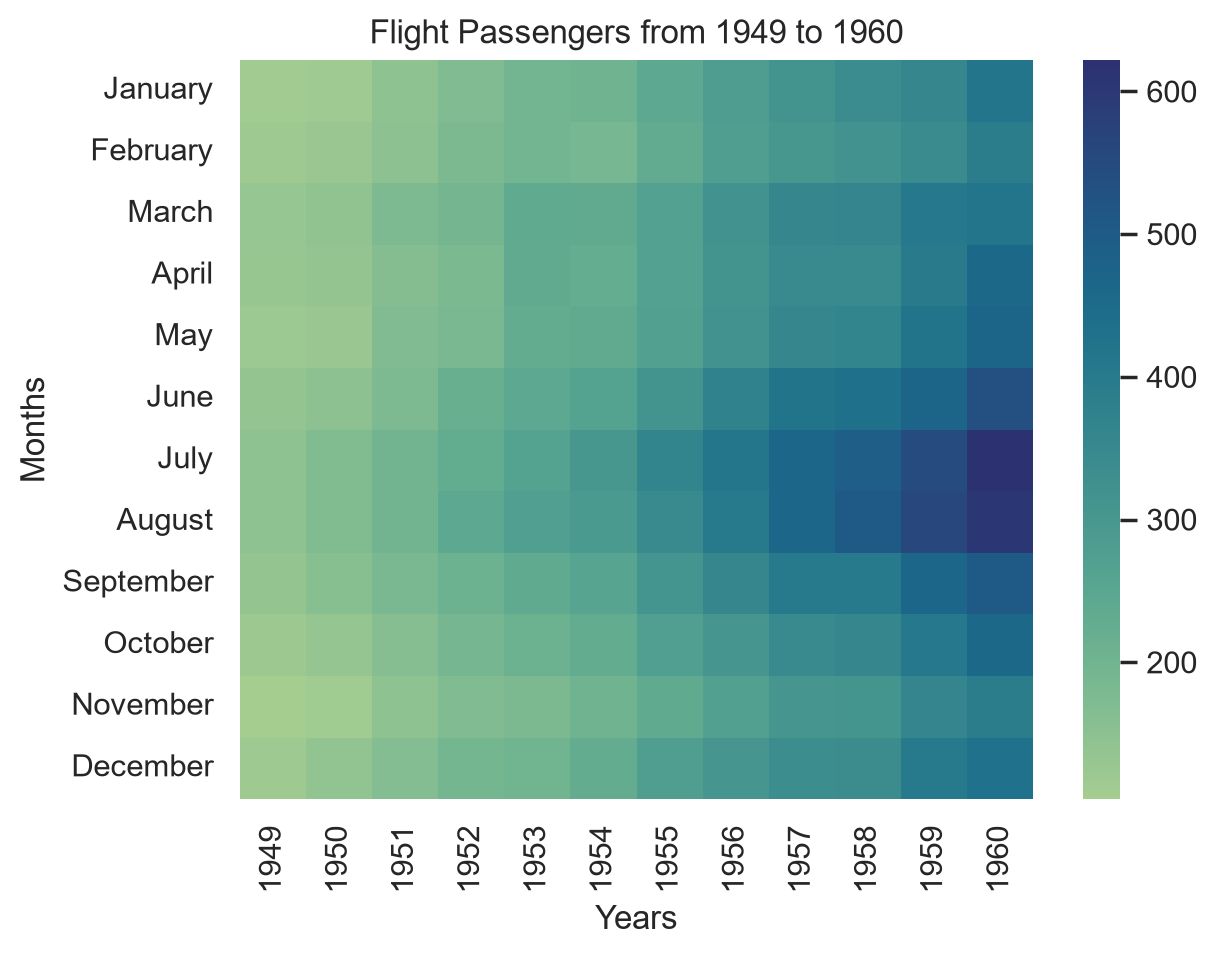

In [7]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set()


raw_data = pd.read_csv("flight_details.csv")
raw_data.columns = raw_data.columns.str.strip()

if 'Month' in raw_data.columns and 'Year' in raw_data.columns:
    data = raw_data.pivot(index='Month', columns='Year', values='Passengers')
elif 'month' in raw_data.columns and 'year' in raw_data.columns:
    data = raw_data.pivot(index='month', columns='year', values='passengers')
else:
   
    data = raw_data.pivot(index=raw_data.columns[0], columns=raw_data.columns[1], values=raw_data.columns[2])
   
    if str(data.index[0]).isdigit():
        data = data.T

months_order = ['January', 'February', 'March', 'April', 'May', 'June', 
                'July', 'August', 'September', 'October', 'November', 'December']

valid_months = [m for m in months_order if m in data.index]
if valid_months:
    data = data.reindex(valid_months)

cmap = sns.color_palette("crest", as_cmap=True)

plt.figure(dpi=200)
sns.heatmap(data, cmap=cmap)


plt.yticks(rotation=0)
plt.xticks(rotation=90)
plt.xlabel("Years")
plt.ylabel("Months")
plt.title("Flight Passengers from 1949 to 1960")

plt.show()